# 15 · Laya: a pretrained decision model, zero-shot

**The question this step answers:** XGBoost and the random forest learned from 12,000 of our own accounts. Can a model that has never seen our data pick the right group just by reading the account and the candidates? That's what "zero-shot" means: no training on this task at all.

**The model:** [Laya](https://huggingface.co/convaiinnovations/laya-multilingual) (`laya-multilingual`, 322M parameters, 100+ languages). It answers typed questions about a text in one forward pass, without generating text. Here it gets one `choice` question per account: which of the 10 shortlisted groups, or "none of these".

**Where it sits in the pipeline:**

```
account name -> shortlist of 10 (07, 12) -> Laya reads the account and the 10 candidates (this step)
             -> its probabilities -> calibration on dev (09) -> auto or review
```

**The code:** `src/d1/mapper/methods/laya_method.py` (`LayaMethod`), `src/d1/mapper/answer_cache.py` (each answer computed once), and one line in `src/d1/__init__.py` that keeps Laya and XGBoost from crashing each other.

**What its authors say, and what this notebook checks:** the base checkpoints are "near chance … zero-shot" on typed decisions; Laya is "a fast base to specialise, not a zero-shot decision engine". They also document a position bias (where an option sits changes the answer) and over-confident probabilities. Sections 2 and 5 measure both here.

*Running this notebook loads bge-m3 and Laya. The dev results come from the evaluation run, whose Laya answers are cached; the experiments on 300 dev accounts take a few minutes.*

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from d1.config import load_config
from d1.datagen.schema import read_jsonl
from d1.datagen.standard_chart import load_standard_chart
from d1.evaluation.metrics import paired_bootstrap_diff
from d1.evaluation.plotting import GRID, INK, INK_2, METHOD_COLORS, SINGLE, apply_style, pct
from d1.mapper.calibrate import reliability_bins
from d1.mapper.embed import MemoEmbedder, SentenceTransformerEmbedder
from d1.mapper.methods.base import accounts_from_rows
from d1.mapper.methods.laya_method import LayaMethod
from d1.mapper.pipeline import Mapper

config = load_config()
chart = load_standard_chart(config.data.chart_path, expected=config.data.expected_groups)
by_code = {a.code: a for a in chart}
apply_style()
pd.set_option("display.max_colwidth", 70)
K = config.models.mapping.candidates_k
METHODS = ["fuzzy", "embeddings", "xgboost", "random_forest", "laya"]

dev = read_jsonl(config.data.generated_dir / "dev.jsonl")
row_of = {r.account_id: r for r in dev}

# The dev runs written by `python -m d1.evaluation.run_mapping --split dev --method <name>`: the newest per method.
runs = {m: sorted((config.root / "reports" / "results").glob(f"*-dev-{m}"))[-1] for m in METHODS}
metrics = {m: json.loads((runs[m] / "metrics.json").read_text()) for m in METHODS}
decisions = {m: pd.read_csv(runs[m] / "decisions.csv", dtype={"chosen_code": str, "target_code": str, "code": str}).set_index("account_id").loc[[r.account_id for r in dev]] for m in METHODS}
for m in METHODS:
    decisions[m]["auto"] = decisions[m].decision_path == "auto"
companies = np.array([r.company_id for r in dev])
print({m: runs[m].name for m in METHODS})

embedder = MemoEmbedder(SentenceTransformerEmbedder(config.models.embedding_model))
mapper = Mapper.from_artifacts(config, "laya", embedder_factory=lambda name: embedder)
laya = mapper.method
laya.progress = False  # the command line prints progress; here it would only clutter the output
retriever = mapper.retriever
print(laya.version())

{'fuzzy': '20261117-070251-dev-fuzzy', 'embeddings': '20261117-070305-dev-embeddings', 'xgboost': '20261117-070331-dev-xgboost', 'random_forest': '20261117-070357-dev-random_forest', 'laya': '20261117-202633-dev-laya'}
laya-convaiinnovations/laya-multilingual@e4e9ddf-rot6-h640-v1-best-group


## 1. One account, as Laya sees it

The account notebooks 13 and 14 followed: **"En-cours chantier Uccle - Av. Brugmann"**, code 320200, right group **320** *Work in Progress*. XGBoost auto-mapped it correctly (notebook 14). Here is the question Laya gets: the account as the *state*, and the 10 shortlisted groups, each with its English, Dutch and French name, plus "none":

In [2]:
row = next(r for r in dev if r.name == "En-cours chantier Uccle - Av. Brugmann")
(account,) = accounts_from_rows([row])
(shortlist,) = retriever.top_k([row.name], K)
print("state:", laya.state(account))
question = laya.question(shortlist)
print("instructions:", question["instructions"])
for label, text in question["criteria"].items():
    print(f"  {label:>4}: {text}")

/Users/vincenzovantornout/Desktop/Work Projects/Work Projects/Data & AI Resume/D1 - Consolidation Copilot/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1117 12:27:26.233000 73174 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 61780.86it/s]

state: {'body': 'En-cours chantier Uccle - Av. Brugmann (code 320200)'}
instructions: Which Belgian standard account group does this company account belong to?
   370: Contracts in Progress - Acquisition Value / Bestellingen in uitvoering - Aanschaffingswaarde / Commandes en cours d'exécution - Valeur d'acquisition
   717: Increase (Decrease) in Contracts in Progress / Toename (Afname) van de bestellingen in uitvoering / Augmentation (Réduction) des commandes en cours d'exécution
   320: Work in Progress - Acquisition Value / Goederen in bewerking - Aanschaffingswaarde / En-cours de fabrication - Valeur d'acquisition
   221: Buildings / Gebouwen / Constructions
   371: Contracts in Progress - Profit Recognized / Bestellingen in uitvoering - Toegerekende winst / Commandes en cours d'exécution - Bénéfice pris en compte
   632: Amounts Written Off Contracts in Progress / Waardeverminderingen op bestellingen in uitvoering / Réductions de valeur sur commandes en cours d'exécution
   712: In

Laya scores all options in one forward pass. The same question is asked under **6 rotations** of the option order (each option in 6 different slots), all in that one pass, and the probabilities are averaged:

In [3]:
agent = laya._get_agent()
start = time.time()
rotated = agent.predict(laya.state(account), laya.questions(shortlist), head_max_len=laya.head_max_len)["answers"]
print(f"{len(rotated)} rotations in one forward pass: {(time.time() - start) * 1000:.0f} ms; shifts {laya.shifts(len(shortlist) + 1)}")
labels = [c.code for c in shortlist] + ["none"]
per_rotation = pd.DataFrame({qid: [a["probabilities"][l] for l in labels] for qid, a in rotated.items()}, index=labels)
table = pd.DataFrame({
    "group": [f"{l} {by_code[l].name_en[:30]}" if l != "none" else "none of these" for l in labels],
    "right?": ["✔" if l == row.target_code else "" for l in labels],
    "cosine": [f"{c.score:.3f}" for c in shortlist] + [""],
    "listed order (shift 0)": per_rotation["q0"].values,
    "picked in how many of the 6 rotations": [int(sum(max(a["probabilities"], key=a["probabilities"].get) == l for a in rotated.values())) for l in labels],
    "average over rotations": per_rotation.mean(axis=1).values,
})
display(table.style.format({"listed order (shift 0)": "{:.3f}", "average over rotations": "{:.3f}"}).hide(axis="index"))
(out,) = laya.score([account], [shortlist])
(decision,) = mapper.map([account], shortlists=[shortlist])
print(f"pick {out.chosen_code} ({out.status}, {out.reason}); calibrated confidence {decision.confidence:.3f}; segment {decision.segment}; decision: {decision.decision_path}")

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Fetching 5 files: 100%|██████████| 5/5 [00:00<00:00, 3875.72it/s]

6 rotations in one forward pass: 2328 ms; shifts [0, 1, 3, 5, 7, 9]


group,right?,cosine,listed order (shift 0),picked in how many of the 6 rotations,average over rotations
370 Contracts in Progress - Acquis,,0.458,0.034,0,0.027
717 Increase (Decrease) in Contrac,,0.445,0.015,0,0.016
320 Work in Progress - Acquisition,✔,0.444,0.260,1,0.142
221 Buildings,,0.430,0.068,0,0.127
371 Contracts in Progress - Profit,,0.430,0.031,0,0.059
632 Amounts Written Off Contracts,,0.423,0.029,0,0.031
712 Increase (Decrease) in Stocks,,0.422,0.018,0,0.034
426 Advance Payments on Contract i,,0.419,0.027,1,0.068
491 Accrued Income,,0.417,0.035,0,0.059
499 Suspense Accounts,,0.417,0.062,0,0.084


pick 320 (ok, laya: leaned to none of these groups (p = 0.35 vs 0.14)); calibrated confidence 0.151; segment code_match; decision: auto


1. **The listed order (shift 0)** gives "none of these" 0.421 and 320 0.260: asked once, Laya would answer "none".
2. **Over the 6 rotations,** "none" wins 4 times, 320 once and 426 once. Averaged, "none" keeps 0.353 and 320 gets 0.142, then 221 *Buildings* 0.127.
3. **"None" doesn't veto the pick** (section 3b): the pick is the best of the 10 groups, **320, which is right**. The reason tells the reviewer that Laya leaned to "none" (0.35 against 0.14).
4. **The calibration decides.** The top score is only 0.142, because "none" kept its share. Calibrated, that's 0.151. But the code 320200 starts with 320, so the account is in the `code_match` segment, whose threshold is 0.105: **auto-mapped**, correctly. XGBoost got it right at 0.995. The baselines picked wrong.

So Laya was unsure, and the account was still auto-mapped. That isn't Laya's own judgement: on dev, a pick its code agrees with is right 98.5% of the time, even at a confidence this low (section 3).


## 2. Position bias: why the question is asked 6 times

Laya's authors measured that where an option sits changes the answer. Here it is on a fixed sample of 300 dev accounts (seeded), asked three ways: once in the listed order, averaged over 6 rotations (the method), and averaged over all 11. None of these uses the cache, so the times are comparable.

sample: 300 dev accounts (146 LLM-written), from 69 companies


asked once: 16 s, 54 ms per account


6 rotations (the method): 65 s, 218 ms per account


all 11 rotations: 115 s, 384 ms per account


,top-1,leans to 'none'
asked once,29.0%,18.0%
6 rotations (the method),38.3%,11.3%
all 11 rotations,38.7%,10.7%


for comparison, the embeddings baseline on the same accounts: top-1 67.3%


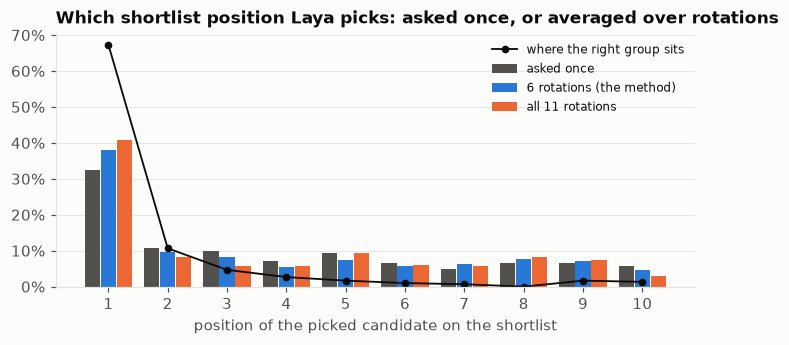

In [4]:
rng = np.random.default_rng(0)
sample = [dev[i] for i in sorted(rng.choice(len(dev), 300, replace=False))]
s_accounts = accounts_from_rows(sample)
s_lists = retriever.top_k([r.name for r in sample], K)
s_target = np.array([r.target_code for r in sample])
print(f"sample: {len(sample)} dev accounts ({sum(r.source == 'llm' for r in sample)} LLM-written), from {len({r.company_id for r in sample})} companies")

# No cache here, so every variant is really asked and timed on the same footing.
variants = {name: LayaMethod(laya.model_id, chart, revision=laya.revision, rotations=n, agent_loader=lambda m, r: agent)
            for name, n in (("asked once", 1), ("6 rotations (the method)", 6), ("all 11 rotations", 11))}
results = {}
for name, method in variants.items():
    start = time.time()
    outs = method.score(s_accounts, s_lists)
    results[name] = outs
    print(f"{name}: {time.time() - start:.0f} s, {(time.time() - start) / len(sample) * 1000:.0f} ms per account")


def summary(outs):
    picks = np.array([o.chosen_code for o in outs])
    leaned = np.array([bool(o.reason) and "leaned to none" in o.reason for o in outs])  # "none" scored above the pick
    slot = [next((i for i, c in enumerate(s) if c.code == o.chosen_code), None) for o, s in zip(outs, s_lists)]
    return {"top-1": np.mean(picks == s_target), "leans to 'none'": leaned.mean(), "slot": slot}


emb_first = np.mean([s[0].code == t for s, t in zip(s_lists, s_target)])
rows = {name: summary(outs) for name, outs in results.items()}
display(pd.DataFrame({n: {k: v for k, v in r.items() if k != "slot"} for n, r in rows.items()}).T.style.format("{:.1%}"))
print(f"for comparison, the embeddings baseline on the same accounts: top-1 {emb_first:.1%}")

fig, ax = plt.subplots(figsize=(7.5, 3))
width = 0.27
right_slot = [next((i for i, c in enumerate(s) if c.code == t), None) for s, t in zip(s_lists, s_target)]
for j, (name, r) in enumerate(rows.items()):
    counts = np.bincount([s for s in r["slot"] if s is not None], minlength=K) / len(sample)
    ax.bar(np.arange(K) + (j - 1) * width, counts, width=width * 0.95, color=[INK_2, SINGLE, "#eb6834"][j], label=name)
ax.plot(np.arange(K), np.bincount([s for s in right_slot if s is not None], minlength=K) / len(sample), color=INK, marker="o", markersize=4, linewidth=1.2, label="where the right group sits")
ax.set_xticks(np.arange(K), [str(i + 1) for i in range(K)])
ax.set_xlabel("position of the picked candidate on the shortlist")
ax.yaxis.set_major_formatter(pct())
ax.grid(axis="x", visible=False)
ax.legend(fontsize=8)
ax.set_title("Which shortlist position Laya picks: asked once, or averaged over rotations")
plt.show()

- **Asked once, top-1 is 29.0%**, and Laya leans to "none" on 18% of the accounts. Averaged over 6 rotations, it's **38.3%** (11.3% lean to "none"); over all 11, 38.7%.
- **The chart shows the bias.** Asked once, Laya picks each of positions 3 to 10 for 5–10% of the accounts, although the right group sits at position 4 or later for under 3% each. Averaging over rotations pulls the picks back to position 1 (33% asked once, 38% over 6 rotations, 41% over 11), where the right group sits for 67%. The bias shrinks, but it doesn't disappear.
- **Why 6 and not 11:** 11 rotations cost 384 ms per account, 6 cost 218 ms (asked once: 54 ms), and the 0.4 points between them are well within noise on 300 accounts (±3 points). 6 keep nearly all of the gain for 57% of the time.
- **The embeddings baseline gets 67.3% on the same 300 accounts.** Even with rotations, Laya is far behind.


## 3. The result on dev: five methods, one bar

From the evaluation run (`python -m d1.evaluation.run_mapping --split dev --method laya`), next to the other four methods. All are calibrated the same way, with one threshold per segment (does the account's code start with the pick?), each held to 98%.

In [5]:
rows = []
for m in METHODS:
    o = metrics[m]["overall"]
    t = metrics[m]["thresholds"]["t_auto_by_segment"]
    rows.append({"method": m, "top-1": o["top1"], "auto-mapped": o["auto_share"], "auto 95%": f"{o['auto_share_ci'][0]:.1%} – {o['auto_share_ci'][1]:.1%}",
                 "precision of auto": o["auto_precision"], "threshold, code agrees": t["code_match"], "threshold, other": t["other"]})
display(pd.DataFrame(rows).set_index("method").style.format({"top-1": "{:.1%}", "auto-mapped": "{:.1%}", "precision of auto": "{:.1%}",
                                                             "threshold, code agrees": "{:.3f}", "threshold, other": "{:.3f}"}, na_rep="–"))
right = {m: (decisions[m].right == 1).values for m in METHODS}
auto = {m: decisions[m].auto.values for m in METHODS}
for b in ("embeddings", "xgboost"):
    for label, values in (("top-1", right), ("auto-mapped", auto)):
        d, lo, hi = paired_bootstrap_diff(values["laya"], values[b], groups=companies)
        print(f"laya − {b}, {label}: {d * 100:+.1f} points ({lo * 100:+.1f} to {hi * 100:+.1f})")
print("Laya's statuses:", decisions["laya"].status.value_counts().to_dict())

,top-1,auto-mapped,auto 95%,precision of auto,"threshold, code agrees","threshold, other"
method,,,,,,
fuzzy,57.9%,29.3%,21.5% – 37.9%,99.8%,0.001,0.942
embeddings,70.3%,35.9%,28.0% – 44.1%,99.7%,0.091,0.999
xgboost,84.5%,74.3%,67.1% – 81.1%,98.5%,0.155,0.933
random_forest,83.6%,74.2%,67.1% – 81.0%,98.5%,0.211,0.925
laya,39.3%,24.3%,18.3% – 30.2%,98.5%,0.105,–


laya − embeddings, top-1: -31.0 points (-36.5 to -25.6)


laya − embeddings, auto-mapped: -11.6 points (-15.5 to -8.1)
laya − xgboost, top-1: -45.2 points (-49.2 to -41.3)
laya − xgboost, auto-mapped: -49.9 points (-56.3 to -43.9)
Laya's statuses: {'ok': 3500}


- **Laya's top-1 is 39.3%,** 31.0 points below the embeddings baseline (interval −36.5 to −25.6) and 45.2 below XGBoost.
- **It auto-maps 24.3% of dev at 98.5%,** all of it where the account's code starts with Laya's pick (threshold 0.105). Where it doesn't, no threshold reaches 98% (the `–`), so all of those accounts go to review. That's the bar working: Laya's names-only picks are never reliable enough.
- **Every account gets a pick** (all statuses `ok`). Laya used to answer "none" on 340 accounts and send them straight to review; section 3b shows why that stopped.
- **Cost:** no money, about 0.2 s per account on the Mac's GPU. The evaluation run took seconds, because every answer was cached from training.


## 3b. "None of these" is a signal, not a veto

Laya can answer "none of these groups". It used to send such an account straight to review. Now the pick is always the best of the 10 groups, and "none" stays only as a signal: the group scores are Laya's own probabilities, not rescaled over the 10, so whatever "none" took lowers the top score, and the calibration sees that. Were the "none" answers right to decline? On all of dev (every answer comes from the cache):

In [6]:
dev_accounts = accounts_from_rows(dev)
dev_lists = retriever.top_k([r.name for r in dev], K)
dev_outs = laya.score(dev_accounts, dev_lists)
target = np.array([r.target_code for r in dev])
leaned = np.array([bool(o.reason) and "leaned to none" in o.reason for o in dev_outs])
on_list = np.array([t in {c.code for c in s} for t, s in zip(target, dev_lists)])
pick_right = np.array([o.chosen_code == t for o, t in zip(dev_outs, target)])
auto_laya = decisions["laya"].auto.values
print(f"cached: {sum(o.cached for o in dev_outs):,} of {len(dev_outs):,}")
display(pd.DataFrame({
    "accounts": [leaned.sum(), (~leaned).sum()],
    "right group on the shortlist": [on_list[leaned].mean(), on_list[~leaned].mean()],
    "pick right": [pick_right[leaned].mean(), pick_right[~leaned].mean()],
    "auto-mapped": [auto_laya[leaned].mean(), auto_laya[~leaned].mean()],
    "precision of auto": [pick_right[leaned & auto_laya].mean() if (leaned & auto_laya).any() else np.nan, pick_right[~leaned & auto_laya].mean()],
}, index=["Laya leaned to 'none'", "a group led"]).style.format({c: "{:.1%}" for c in ["right group on the shortlist", "pick right", "auto-mapped", "precision of auto"]}, na_rep="–"))
print(f"shortlist misses: {(~on_list).sum()}; Laya leaned to 'none' on {leaned[~on_list].mean():.1%} of them, and on {leaned[on_list].mean():.1%} of the hits")

cached: 3,500 of 3,500


,accounts,right group on the shortlist,pick right,auto-mapped,precision of auto
Laya leaned to 'none',340,80.9%,17.6%,10.9%,100.0%
a group led,3160,93.8%,41.6%,25.8%,98.4%


shortlist misses: 260; Laya leaned to 'none' on 25.0% of them, and on 8.5% of the hits


- **"None" was mostly hesitation.** On 275 of the 340 accounts where Laya leaned to "none" (80.9%), the right group *was* on the shortlist. It wasn't saying "it isn't there"; it was unsure.
- **But it does carry a signal.** Laya leans to "none" on 25.0% of the 260 shortlist misses, against 8.5% of the hits: three times as often when the right group really is missing. Its pick on those accounts is right only 17.6% of the time, against 41.6% when a group led.
- **That's why it is kept as a signal, not a veto.** The group scores aren't rescaled over the 10 groups, so a strong "none" leaves a low top score, and the calibration sends those accounts to review. Only 37 of the 340 (10.9%) were auto-mapped, all through the code segment (the code agrees with the pick), and **all 37 were right**.
- **Before and after on dev:** top-1 37.6% → **39.3%** (the 60 "none" accounts whose best group was right now count), auto-mapped 23.3% → **24.3%** (+37 accounts), precision 98.4% → 98.5%. Nothing had to be asked again: the question didn't change, so every answer came from the cache.


## 4. Where Laya stands: by source and code scheme, and against XGBoost

In [7]:
seg = pd.Series([f"{r.source} · {r.code_scheme}" for r in dev], index=decisions["laya"].index)
out = []
for value in sorted(seg.unique()):
    s = (seg == value).values
    for m in ("embeddings", "xgboost", "laya"):
        a = auto[m] & s
        out.append({"segment": value, "accounts": int(s.sum()), "method": m, "top-1": right[m][s].mean(), "auto-mapped": a.sum() / s.sum(),
                    "precision of auto": right[m][a].mean() if a.any() else np.nan})
display(pd.DataFrame(out).pivot(index=["segment", "accounts"], columns="method", values=["top-1", "auto-mapped", "precision of auto"]).style.format("{:.1%}", na_rep="–"))

both = pd.crosstab(pd.Series(np.where(right["xgboost"], "XGBoost right", "XGBoost wrong"), name=""), pd.Series(np.where(right["laya"], "Laya right", "Laya wrong"), name=""))
display(both)
rescue = ~right["xgboost"] & right["laya"]
print(f"Laya right where XGBoost is wrong: {rescue.sum()} accounts ({rescue.mean():.1%} of dev)")
display(pd.DataFrame([{"account": row_of[a].name, "code": row_of[a].code, "right group": f"{row_of[a].target_code} {by_code[row_of[a].target_code].name_en[:28]}",
                       "XGBoost": decisions["xgboost"].loc[a, "chosen_code"], "Laya": decisions["laya"].loc[a, "chosen_code"]}
                      for a in decisions["laya"].index[rescue][:8]]).style.hide(axis="index"))

,Laya right,Laya wrong
,,
XGBoost right,1327,1631
XGBoost wrong,49,493


Laya right where XGBoost is wrong: 49 accounts (1.4% of dev)


account,code,right group,XGBoost,Laya
OTTHER NON-RECURRING FIN. INCO,2830,769 Other Non-Recurring Financia,764,769
Voorzieningen voor milieuverplichtingen,3370,637 Provisions for Environmental,163,637
Wisselresultaten - oud,3410,654 Exchange Differences,754,654
PROV. POUR OBLIGATIONS ENVIRONNEMENTALES,1720,637 Provisions for Environmental,163,637
PROV. POUR OBLIGATIONS ENVIRONNEMENTALES - Namur,1730,637 Provisions for Environmental,163,637
CHARGES D'EXPLOITATION PORTÉES,6640,649 Operating Charges Carried to,664,649
"REMUN., PREMIUMS FOR EXTRA STA",1320,"618 Remuneration, Premiums for E",622,618
Diverse vord. - oud,5000,416 Sundry Amounts Receivable,743,416


- **Laya's auto-mapping comes from the code.** PCMN-coded accounts: 54.5% auto-mapped at 99.4%; LLM-coded: 37.5% at 99.0%. Legacy codes: 0.1% and 0.6%, all wrong (a legacy code that happens to start with Laya's pick).
- **On names alone it is weak:** top-1 34.6% on rule-based legacy accounts, where embeddings gets 89.4% and XGBoost 93.3%.
- **Is Laya right where XGBoost is wrong?** On 49 accounts (1.4% of dev). But look at them: most are **mirror groups**, pairs with identical names in all three languages (637 and 163 *Provisions for Environmental Obligations*, 654 and 754 *Exchange Differences*). No method can tell those apart from the name, so on those Laya was lucky, not better. That's useful to know before the ensemble (Task 3.7): Laya would add little there.


## 5. Over-confidence, and what calibration does

Laya's own top probability against how often it is right, on the 300 sampled accounts, then the same after calibration on dev:

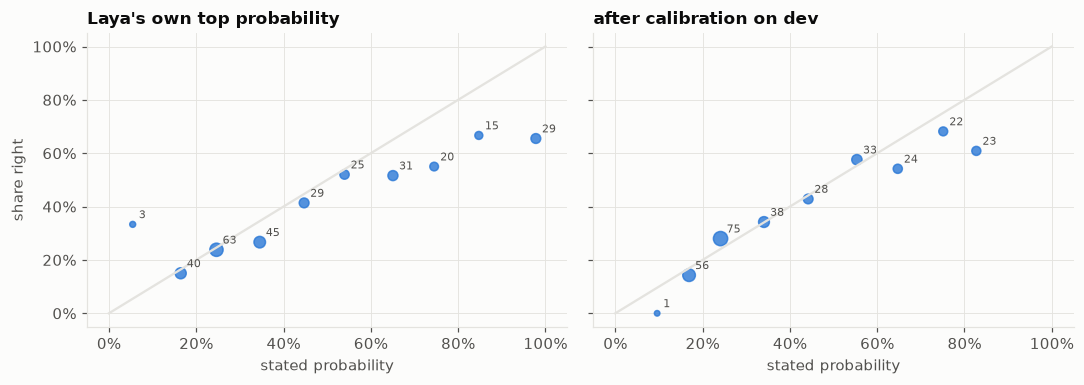

stated above 90%: 10% of picks; right among those: 66%


In [8]:
outs = results["6 rotations (the method)"]
picked = np.array([o.chosen_code is not None for o in outs])
s1 = np.array([max(o.scores.values()) if o.scores else 0.0 for o in outs])
ok = np.array([o.chosen_code == t for o, t in zip(outs, s_target)])
confidence = np.array([d.confidence for d in mapper.map(s_accounts, shortlists=s_lists)])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, values, title in ((axes[0], s1, "Laya's own top probability"), (axes[1], confidence, "after calibration on dev")):
    bins = reliability_bins(values[picked], ok[picked], n_bins=10)
    ax.plot([0, 1], [0, 1], color=GRID, linewidth=1.5)
    ax.scatter([b["mean_p"] for b in bins], [b["accuracy"] for b in bins], s=[12 + b["n"] for b in bins], color=SINGLE, alpha=0.8)
    for b in bins:
        ax.annotate(str(b["n"]), (b["mean_p"], b["accuracy"]), xytext=(4, 4), textcoords="offset points", fontsize=7, color=INK_2)
    ax.set_xlabel("stated probability"); ax.set_title(title)
    ax.xaxis.set_major_formatter(pct()); ax.yaxis.set_major_formatter(pct())
axes[0].set_ylabel("share right")
plt.tight_layout(); plt.show()
print(f"stated above 90%: {np.mean(s1[picked] > 0.9):.0%} of picks; right among those: {ok[picked][s1[picked] > 0.9].mean():.0%}")

- **Laya's own probabilities are too sure at the top:** picks it gives above 90% (10% of its picks) are right 66% of the time. In the middle they're closer to honest, partly because averaging 6 rotations already softens the extremes. At the bottom are the accounts where "none" took most of the probability.
- **After calibration** (two numbers per account: the top probability and its lead, as for every method), the points sit near the diagonal: a stated 60% is right about 60% of the time. That's what makes the per-segment thresholds trustworthy for Laya too.
- **The authors say the same:** the multilingual checkpoint "ships with no fitted temperatures", so its probabilities shouldn't be relied on as they come.


## 6. Does Laya read the code?

The same 300 accounts, with the account code left out of what Laya reads:

In [9]:
no_code_accounts = [a.model_copy(update={"code": None}) for a in s_accounts]
start = time.time()
no_code = variants["6 rotations (the method)"].score(no_code_accounts, s_lists)
print(f"without the code: {time.time() - start:.0f} s")
prefix = np.array([bool(r.code) and r.code.startswith(r.target_code) for r in sample])
rows = []
for name, o in (("with the code (the method)", outs), ("without the code", no_code)):
    p = np.array([x.chosen_code == t for x, t in zip(o, s_target)])
    rows.append({"input": name, "top-1": p.mean(), "code starts with the right group": p[prefix].mean(), "legacy code": p[~prefix].mean()})
display(pd.DataFrame(rows).set_index("input").style.format("{:.1%}"))
print(f"{prefix.sum()} of the {len(sample)} sampled accounts have a code that starts with the right group")

without the code: 63 s


,top-1,code starts with the right group,legacy code
input,,,
with the code (the method),38.3%,49.0%,28.1%
without the code,27.0%,25.2%,28.8%


147 of the 300 sampled accounts have a code that starts with the right group


- **Without the code, top-1 falls from 38.3% to 27.0%.** On accounts whose code starts with the right group, it falls from 49.0% to 25.2%. On legacy codes it barely moves (28.1% to 28.8%).
- **So Laya does read the code:** the option labels are the group codes ("320"), and "code 320200" in the account text matches one. That's the same signal XGBoost gets from `code_prefix_match`, picked up from the text instead of a feature.
- **On the name alone, Laya gets about a quarter right,** against 67% for the embeddings baseline on the same accounts. As its authors put it: a fast base to specialise, not a zero-shot decision engine.


## 7. What is *not* happening

- **No training on our data.** Laya is used exactly as published, pinned to the revision its authors list as reviewed. Only the calibrator (three numbers) and the thresholds are fitted, on dev, as for every method.
- **No fine-tuning.** The authors' own advice is to fine-tune Laya on in-domain decisions; that would make it a learned method like XGBoost, trained on the same 12,000 accounts. It's a possible later step, not part of the zero-shot comparison.
- **No money.** Laya runs on the Mac's GPU. Its cost is time, which is in the cost column of section 3.
- **The test split is not touched.** Every number here is on dev, or on a fixed sample of 300 dev accounts.